# Método de diferencias divididas para completar el polinomio de Newton

 Permite encontrar el polinomio de interpolación $P_n(x)$ que pasa exactamente por un conjunto de $(n + 1)$ puntos distintos $(x_0, f(x_0)), (x_1, f(x_1)), \dots, (x_n, f(x_n))$.

 Para la fórmula del Polinomio de Interpolación de grado $n$ se construye de forma recursiva mediante:
   $$P_n(x) = f[x_0] + \sum_{k=1}^{n} f[x_0, x_1, \dots, x_k](x - x_0)(x - x_1)\cdots(x - x_{k-1})$$   Donde cada coeficiente $a_k = f[x_0, x_1, \dots, x_k]$ se denomina diferencia dividida de orden $k$.   

Se colocan los datos conocidos en la primera columna de una tabla, definiendo las diferencias divididas de orden cero como los mismos valores de la función:
$$F_{i,0} = f[x_i] = f(x_i) \quad \text{para } i = 0, 1, \dots, n$$

Se calculan las columnas siguientes de izquierda a derecha usando la relación de recurrencia:

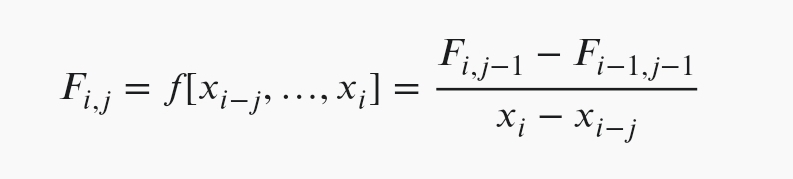

Una vez completada la tabla triangular, se toman únicamente los términos de la diagonal superior

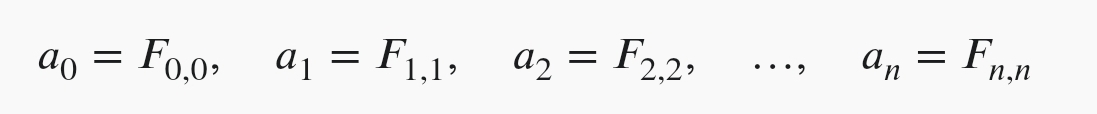

Sustituyendo éstos en la fórmula anterior, generará el polinomio de interpolación.


Tabla de diferencias divididas:
[[ 0.765198  0.        0.        0.        0.      ]
 [ 0.620086 -0.483706  0.        0.        0.      ]
 [ 0.455402 -0.548946 -0.108734  0.        0.      ]
 [ 0.281819 -0.578612 -0.049443  0.065878  0.      ]
 [ 0.110362 -0.571521  0.011818  0.068069  0.001825]]

Polinomio P(x) = 0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085


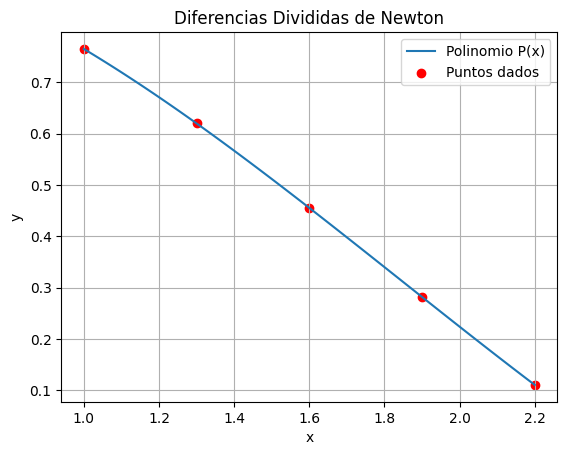

0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

def diferencias_divididas(x_datos, y_datos):
    x = sp.symbols('x')
    n = len(x_datos)

    F = np.zeros((n, n))
    F[:, 0] = y_datos

    for i in range(1, n):
        for j in range(1, i + 1):#Ayuda de IA con la formulación del buble for para generar las columnas de las tablas de acuerdo al algoritmo
            F[i, j] = (F[i, j-1] - F[i-1, j-1]) / (x_datos[i] - x_datos[i-j])

    P = F[0, 0]
    multiplicacion = 1
    for i in range(1, n):
        multiplicacion = multiplicacion * (x - x_datos[i-1])
        P = P + F[i, i] * multiplicacion

    P = sp.expand(P)

    print("Tabla de diferencias divididas:")
    print(np.round(F, 6))
    print("\nPolinomio P(x) =", P)

    f_grafica = sp.lambdify(x, P, 'numpy')
    x_linea = np.linspace(min(x_datos), max(x_datos), 100)

    plt.plot(x_linea, f_grafica(x_linea), label='Polinomio P(x)')
    plt.scatter(x_datos, y_datos, color='red', label='Puntos dados')
    plt.title('Diferencias Divididas de Newton')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.grid(True)
    plt.legend()
    plt.show()

    return P

x_vals = [1.0, 1.3, 1.6, 1.9, 2.2]
y_vals = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

diferencias_divididas(x_vals, y_vals)